<a href="https://colab.research.google.com/github/Hasini-uni/DAVlab/blob/main/lab7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error
import numpy as np

df = pd.read_csv("/content/StudentPerformanceFactors[1].csv")

print("Dataset:")
df


Dataset:


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6602,25,69,High,Medium,No,7,76,Medium,Yes,1,High,Medium,Public,Positive,2,No,High School,Near,Female,68
6603,23,76,High,Medium,No,8,81,Medium,Yes,3,Low,High,Public,Positive,2,No,High School,Near,Female,69
6604,20,90,Medium,Low,Yes,6,65,Low,Yes,3,Low,Medium,Public,Negative,2,No,Postgraduate,Near,Female,68
6605,10,86,High,High,Yes,6,91,High,Yes,2,Low,Medium,Private,Positive,3,No,High School,Far,Female,68


In [4]:
# Simple Linear Regression
X_simple = df[["Hours_Studied"]]

# Multiple Linear Regression
X_multiple = df[
    ["Hours_Studied", "Attendance", "Previous_Scores"]
]

y = df["Exam_Score"]

X_train_s, X_test_s, y_train, y_test = train_test_split(
    X_simple, y, test_size=0.2, random_state=42
)

X_train_m, X_test_m, _, _ = train_test_split(
    X_multiple, y, test_size=0.2, random_state=42
)

In [5]:
#simple linear regression
simple_model = LinearRegression()
simple_model.fit(X_train_s, y_train)

simple_predictions = simple_model.predict(X_test_s)

print("--- Simple Linear Regression ---")
print("Intercept:", simple_model.intercept_)
print("Coefficient:", simple_model.coef_[0])
print("R2 Score:", r2_score(y_test, simple_predictions))
print("RMSE:", np.sqrt(
    mean_squared_error(y_test, simple_predictions)
))

--- Simple Linear Regression ---
Intercept: 61.51116746904424
Coefficient: 0.285668744443087
R2 Score: 0.2319868674542106
RMSE: 3.294832513010839


In [6]:
#multiple linear regression
multiple_model = LinearRegression()
multiple_model.fit(X_train_m, y_train)

multiple_predictions = multiple_model.predict(X_test_m)

print("--- Multiple Linear Regression ---")
print("Intercept:", multiple_model.intercept_)
print("Coefficients:", multiple_model.coef_)
print("R2 Score:", r2_score(y_test, multiple_predictions))
print("RMSE:", np.sqrt(
    mean_squared_error(y_test, multiple_predictions)
))

--- Multiple Linear Regression ---
Intercept: 42.00637955940461
Coefficients: [0.28749797 0.19913445 0.04746368]
R2 Score: 0.6223383752199567
RMSE: 2.3104706093257077


In [7]:
#Predict marks for a new student
# Simple Regression
new_student_simple = pd.DataFrame({
    "Hours_Studied": [6]
})

# Multiple Regression
new_student_multiple = pd.DataFrame({
    "Hours_Studied": [6],
    "Attendance": [80],
    "Previous_Scores": [70]
})

print(
    "Predicted marks using Simple Regression:",
    simple_model.predict(new_student_simple)[0]
)

print(
    "Predicted marks using Multiple Regression:",
    multiple_model.predict(new_student_multiple)[0]
)

Predicted marks using Simple Regression: 63.22517993570276
Predicted marks using Multiple Regression: 62.984581476561814


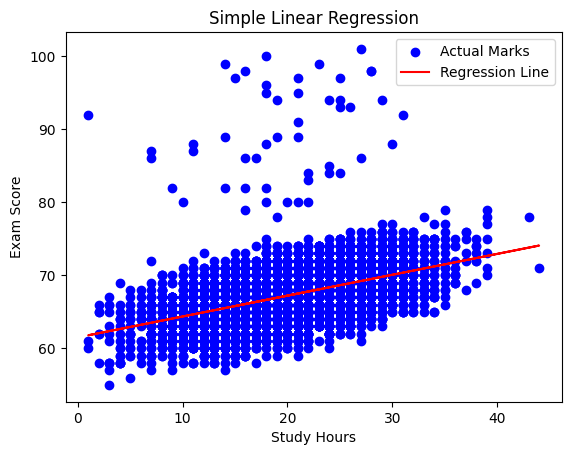

In [8]:
#Plot Simple Linear Regression
plt.scatter(
    df["Hours_Studied"],
    df["Exam_Score"],
    color="blue",
    label="Actual Marks"
)

plt.plot(
    df["Hours_Studied"],
    simple_model.predict(X_simple),
    color="red",
    label="Regression Line"
)

plt.xlabel("Study Hours")
plt.ylabel("Exam Score")
plt.title("Simple Linear Regression")
plt.legend()
plt.show()